C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\1544391064.py:28: RuntimeWarning: divide by zero encountered in log
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\1544391064.py:28: RuntimeWarning: invalid value encountered in multiply
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\1544391064.py:28: RuntimeWarning: divide by zero encountered in divide
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)


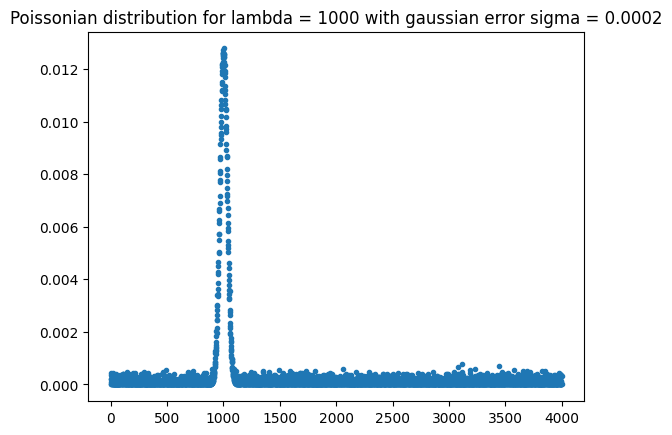

In [6]:
# play around with poissonian
import numpy as np
import math
from matplotlib import pyplot as plt
from scipy.special import factorial

n = 4000
n_max =  n-1
A = 1
lam =   1000
sigma = 0.0002
k_list = np.linspace(0,n_max,n)

np.random.seed(0) # for reproducibility

def poissonian(k, lam):
    a = pow(lam, k)
    b = np.exp(-lam)
    c = factorial(k)
    return  a*b/c

def poissonian2(A, k, lam): # optimized for large values of k and lam
    ln_a = k* np.log(lam)
    ln_b = -lam
    ln_c = np.log(factorial(k))
    if isinstance(k,np.ndarray):
        if len(k)>500: # Stirling approximation to 4th order for large k
            ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
    return  A * np.exp(ln_a + ln_b - ln_c)

def poissonian_with_gaussian_err(k, lam, sigma):
    a = pow(lam, k)
    b = np.exp(-lam)
    c = factorial(k)
    return  k + np.random.normal(0,sigma)

gaussian_error_list = [np.random.normal(0,sigma) for i in k_list]
for a in range(len(gaussian_error_list)):
    if gaussian_error_list[a]<0:
        gaussian_error_list[a]=0
poisson_signal_list = poissonian2(A, k_list, lam=lam)
signal_with_noise_list = poisson_signal_list+gaussian_error_list

plt.plot(k_list, signal_with_noise_list, '.')
plt.title(f"Poissonian distribution for lambda = {lam} with gaussian error sigma = {sigma}")
#plt.legend()
plt.show()